# 01 · SHD: predizione per singola condizione e ricerca di sottogruppi

**Obiettivo.** Il target `shd_moderate_or_greater_flag` è un OR di 11 condizioni diverse (LVEF ridotta, ipertrofia, valvulopatie, disfunzione del ventricolo destro, ipertensione polmonare, versamento). Condizioni diverse lasciano tracce diverse sull'ECG, quindi nel composito si diluiscono a vicenda.

Questo notebook risponde a tre domande:
1. **Per quali condizioni** le feature ECG tabulari predicono bene?
2. **Per quali gruppi di pazienti** (QRS, sesso, età, setting, etnia) il modello globale funziona meglio, e un modello dedicato al gruppo migliora?
3. **Ci sono sottogruppi** (regole del tipo `QRS ≥ 120 e età > 65`) in cui la predizione è nettamente più accurata? Le regole vengono **scoperte sul train** e **verificate su validation**.

Tutti i numeri sono su validation con IC95%. Il test set resta intatto.

In [1]:
#@title Setup comune: configurazione, caricamento dati, funzioni di utilità
import os, sys, time, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
warnings.filterwarnings("ignore")

# ===================== CONFIGURAZIONE =====================
DATA_DIR = Path(os.environ.get("ECHONEXT_DIR", "/home/idalab/Desktop/Teo/physionet.org/files/echonext/1.1.1"))   # cartella con lo zip (o i file già estratti)
OUT_DIR  = Path(os.environ.get("ECHONEXT_OUT", str(Path.home() / "echonext_results")))  # dove salvare i risultati
SEED = 42
DEBUG_N = int(os.environ.get("ECHONEXT_DEBUG_N", "0")) or None  # es. 3000 = prova rapida con 3000 righe per split
RUN_FINAL_TEST = False   # lasciare False finché pipeline e scelte non sono congelate (vedi ultima cella)
TARGET = "shd_moderate_or_greater_flag"
# ==========================================================

def locate_dataset(root):
    """Trova il CSV dei metadati (anche in sottocartelle, anche .csv.gz); se c'è solo uno zip lo estrae in <root>/extracted.
    Se non trova nulla, stampa il contenuto della cartella per capire cosa manca."""
    import zipfile
    root = Path(root).expanduser()
    if not root.exists(): raise FileNotFoundError(f"Cartella non trovata: {root}")
    def find_csv(base):
        c = [p for p in base.rglob("*") if p.is_file() and "metadata" in p.name.lower() and p.name.lower().endswith((".csv", ".csv.gz"))]
        return sorted(c, key=lambda p: ("100k" not in p.name.lower(), len(str(p))))
    hits = find_csv(root)
    if hits: return hits[0]
    target = root / "extracted"
    for z in sorted(root.rglob("*.zip")):
        with zipfile.ZipFile(z) as zf:
            if any("metadata" in n.lower() and ".csv" in n.lower() for n in zf.namelist()):
                print(f"estraggo {z.name} in {target} ... (può richiedere minuti)"); zf.extractall(target); break
    hits = find_csv(target) if target.exists() else []
    if hits: return hits[0]
    files = sorted(p for p in root.rglob("*") if p.is_file())
    listing = "\n".join(f"  {p.relative_to(root)}  ({p.stat().st_size / 1e6:.2f} MB)" for p in files[:30])
    raise FileNotFoundError(f"Nessun CSV di metadata in {root}.\nContenuto trovato ({len(files)} file):\n{listing or '  (nessun file)'}\n"
                            "Se vedi solo index.html o file di pochi KB il download non è andato a buon fine (credenziali o DUA non firmato); "
                            "se i file stanno altrove, punta DATA_DIR alla cartella giusta.")

META_PATH = locate_dataset(DATA_DIR)
DATA_DIR = META_PATH.parent
print("dati in:", DATA_DIR)
OUT_DIR.mkdir(parents=True, exist_ok=True)
np.random.seed(SEED)

# Feature ECG ammesse come INPUT dei modelli (misure automatiche dell'ECG + demografia)
ECG_FEATURES = ["sex", "ventricular_rate", "atrial_rate", "pr_interval", "qrs_duration", "qt_corrected", "age_at_ecg"]
# Etichette binarie derivate dall'ecocardiogramma (possibili TARGET)
FLAG_COLS = ["shd_moderate_or_greater_flag", "lvef_lte_45_flag", "lvwt_gte_13_flag",
             "aortic_stenosis_moderate_or_greater_flag", "aortic_regurgitation_moderate_or_greater_flag",
             "mitral_regurgitation_moderate_or_greater_flag", "tricuspid_regurgitation_moderate_or_greater_flag",
             "pulmonary_regurgitation_moderate_or_greater_flag", "rv_systolic_dysfunction_moderate_or_greater_flag",
             "pericardial_effusion_moderate_large_flag", "pasp_gte_45_flag", "tr_max_gte_32_flag"]
# Colonne derivate dall'eco: MAI usarle come input (leakage del target)
ECHO_ONLY_COLS = ["aortic_stenosis_value", "aortic_regurgitation_value", "mitral_regurgitation_value",
                  "tricuspid_regurgitation_value", "pulmonary_regurgitation_value", "rv_systolic_function_value",
                  "pericardial_effusion_value", "ivs_measurement", "lvpw_measurement", "pasp_value",
                  "tr_max_velocity_value", "lvef_value"] + FLAG_COLS
assert not set(ECG_FEATURES) & set(ECHO_ONLY_COLS), "leakage: feature eco tra gli input"

# ---------- caricamento metadata ----------
meta = pd.read_csv(META_PATH)
meta["sex"] = meta["sex"].astype(str).str.lower().map({"male": 1, "female": 0, "m": 1, "f": 0, "1": 1, "0": 0, "1.0": 1, "0.0": 0})
assert meta["sex"].notna().mean() > 0.9, "colonna sex non interpretata: controlla i valori"
# l'ordine delle righe del CSV corrisponde all'ordine dei file .npy di ciascuno split
meta["row_in_split"] = meta.groupby("split").cumcount()
if DEBUG_N:
    meta = meta.groupby("split").head(DEBUG_N)
train, val, test = (meta[meta.split == s].copy() for s in ("train", "val", "test"))
print(f"train={len(train):,}  val={len(val):,}  test={len(test):,}  (no_split={int((meta.split=='no_split').sum()):,})")

# ---------- metriche ----------
from sklearn.metrics import roc_auc_score, average_precision_score, mean_absolute_error, r2_score

def safe_auc(y, p):
    y = np.asarray(y)
    return roc_auc_score(y, p) if len(np.unique(y)) == 2 else np.nan

def boot_ci(y, p, fn=safe_auc, n=300, seed=0):
    """Intervallo di confidenza al 95% per bootstrap sulle righe (val/test hanno 1 ECG per paziente)."""
    rng = np.random.default_rng(seed); y = np.asarray(y); p = np.asarray(p); vals = []
    for _ in range(n):
        i = rng.integers(0, len(y), len(y)); v = fn(y[i], p[i])
        if not np.isnan(v): vals.append(v)
    return (np.percentile(vals, 2.5), np.percentile(vals, 97.5)) if vals else (np.nan, np.nan)

def fmt_auc(y, p):
    lo, hi = boot_ci(y, p)
    return safe_auc(y, p), lo, hi

# ---------- dati e modelli ----------
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import GroupKFold, cross_val_predict

def get_xy(df, target, features=ECG_FEATURES):
    """Restituisce X, y, df filtrato (righe con target mancante escluse)."""
    d = df.dropna(subset=[target])
    y = d[target].values
    y = y.astype(int) if target in FLAG_COLS else y.astype(float)
    return d[list(features)].astype(float), y, d

def model_zoo(seed=SEED):
    """Più modelli da confrontare: lineare, lineare sparso (Lasso), foresta, boosting, rete densa (MLP)."""
    imp = lambda: SimpleImputer(strategy="median", add_indicator=True)  # l'indicatore cattura "PR/atrial rate mancante" (es. fibrillazione)
    return {
        "logreg": make_pipeline(imp(), StandardScaler(), LogisticRegression(max_iter=2000, C=1.0)),
        "lasso_logreg": make_pipeline(imp(), StandardScaler(), LogisticRegression(penalty="l1", solver="liblinear", C=0.1)),
        "random_forest": make_pipeline(imp(), RandomForestClassifier(n_estimators=300, min_samples_leaf=20, n_jobs=-1, random_state=seed)),
        "hist_gb": HistGradientBoostingClassifier(max_depth=4, learning_rate=0.05, max_iter=250, random_state=seed),
        "mlp_dense": make_pipeline(imp(), StandardScaler(), MLPClassifier(hidden_layer_sizes=(64, 32), alpha=1e-3, early_stopping=True, max_iter=200, random_state=seed)),
    }

def eval_models(Xtr, ytr, Xva, yva, models=None):
    """Addestra su train, valuta su val. Ritorna tabella AUROC (con IC95%) e predizioni."""
    rows, preds = [], {}
    for name, m in (models or model_zoo()).items():
        t0 = time.time(); m.fit(Xtr, ytr); p = m.predict_proba(Xva)[:, 1]
        a, lo, hi = fmt_auc(yva, p)
        rows.append(dict(model=name, AUROC=a, CI_lo=lo, CI_hi=hi, AUPRC=average_precision_score(yva, p),
                         prev_val=float(np.mean(yva)), n_val=len(yva), sec=round(time.time() - t0, 1)))
        preds[name] = p
    return pd.DataFrame(rows).sort_values("AUROC", ascending=False).reset_index(drop=True), preds

def oof_proba(model, X, y, groups, n_splits=5):
    """Predizioni out-of-fold con CV raggruppata per paziente (nessun paziente in train e test dello stesso fold)."""
    return cross_val_predict(model, X, y, groups=groups, cv=GroupKFold(n_splits), method="predict_proba")[:, 1]

def add_groups(df):
    """Aggiunge fasce di QRS ed età, usate per stratificare."""
    d = df.copy()
    d["qrs_bin"] = pd.cut(d.qrs_duration, [0, 100, 120, 10000], labels=["<100", "100-119", ">=120"], right=False).astype(object)
    d["age_bin"] = pd.cut(d.age_at_ecg, [0, 50, 65, 75, 200], labels=["<50", "50-64", "65-74", ">=75"], right=False).astype(object)
    return d

dati in: /home/idalab/Desktop/Teo/physionet.org/files/echonext/1.1.1
train=72,475  val=4,626  test=5,442  (no_split=17,457)


## 1 · Una predizione per ciascuna condizione

Si addestrano modelli sul train e si valuta l'AUROC su validation per il composito e per ciascun flag. Le righe con etichetta mancante (ECG senza eco entro un anno) vengono escluse target per target. Le condizioni con troppo pochi positivi sono saltate.

model,hist_gb,logreg,mlp_dense,prev_val
target,,,,
aortic_stenosis_moderate_or_greater_flag,0.844,0.842,0.830,0.054
mitral_regurgitation_moderate_or_greater_flag,0.767,0.770,0.763,0.061
lvef_lte_45_flag,0.764,0.758,0.756,0.187
rv_systolic_dysfunction_moderate_or_greater_flag,0.764,0.743,0.745,0.080
tricuspid_regurgitation_moderate_or_greater_flag,0.753,0.747,0.756,0.066
shd_moderate_or_greater_flag,0.746,0.738,0.745,0.430
lvwt_gte_13_flag,0.686,0.676,0.684,0.190
pasp_gte_45_flag,0.685,0.683,0.688,0.126
tr_max_gte_32_flag,0.673,0.688,0.665,0.058


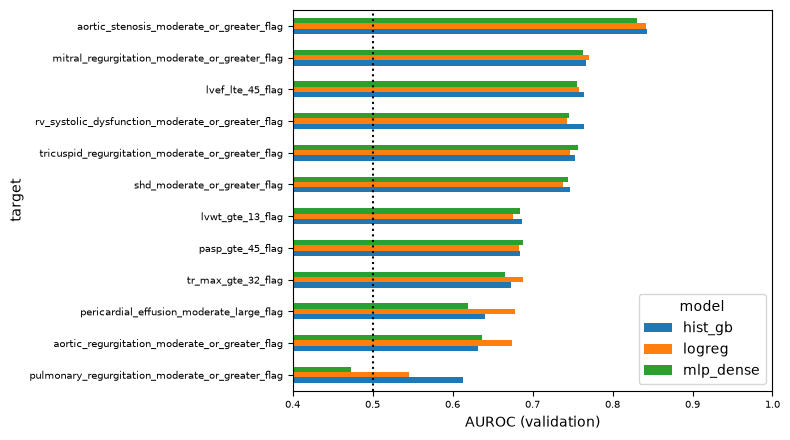

In [2]:
FAST_MODELS = ("logreg", "hist_gb", "mlp_dense")   # aggiungi "random_forest" per un confronto più ampio
rows = []
for tgt in [TARGET] + [c for c in FLAG_COLS if c != TARGET]:
    Xtr, ytr, _ = get_xy(train, tgt); Xva, yva, _ = get_xy(val, tgt)
    if ytr.sum() < 30 or yva.sum() < 10:
        print("saltato (pochi positivi):", tgt, f"(train={int(ytr.sum())}, val={int(yva.sum())})"); continue
    zoo = {k: v for k, v in model_zoo().items() if k in FAST_MODELS}
    r, _ = eval_models(Xtr, ytr, Xva, yva, zoo)
    for _, x in r.iterrows():
        rows.append(dict(target=tgt, model=x.model, AUROC=x.AUROC, CI_lo=x.CI_lo, CI_hi=x.CI_hi,
                         prev_val=x.prev_val, n_pos_val=int(round(x.prev_val * x.n_val))))
per_cond = pd.DataFrame(rows)
per_cond.to_csv(OUT_DIR / "01_per_condizione.csv", index=False)
piv = per_cond.pivot(index="target", columns="model", values="AUROC")
piv["prev_val"] = per_cond.groupby("target").prev_val.first()
display(piv.sort_values(list(piv.columns[:1]), ascending=False).round(3))

fig, ax = plt.subplots(figsize=(8, 4.5))
piv.drop(columns="prev_val").sort_values("hist_gb").plot.barh(ax=ax)
ax.axvline(0.5, color="k", ls=":"); ax.set_xlim(0.4, 1); ax.set_xlabel("AUROC (validation)"); ax.tick_params(labelsize=7)
plt.tight_layout(); plt.show()

**Come leggere.** Le condizioni con AUROC nettamente più alto del composito sono i primi candidati su cui costruire un modello dedicato. Attenzione: scegliere il "miglior modello" guardando la validation introduce un piccolo ottimismo; il numero definitivo si ottiene una sola volta sul test set (ultima cella).

## 2 · Stratificazione per gruppi noti

Per ogni gruppo (QRS, sesso, età, setting, etnia) si confronta:
- il **modello globale** (addestrato su tutti i pazienti) valutato solo sui pazienti del gruppo;
- un **modello locale** addestrato solo sui pazienti del gruppo.

`race_ethnicity` e `location_setting` non sono usate come input: servono solo a stratificare la valutazione e a controllare equità tra gruppi.

In [3]:
tr_all, va_all = add_groups(train), add_groups(val)
Xtr, ytr, dtr = get_xy(tr_all, TARGET); Xva, yva, dva = get_xy(va_all, TARGET)
glob = model_zoo()["hist_gb"].fit(Xtr, ytr)
pva = glob.predict_proba(Xva)[:, 1]
print("AUROC globale (validation):", [round(v, 3) for v in fmt_auc(yva, pva)])

def local_model():
    return HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=150, random_state=SEED)

def subgroup_report(col, min_val=100, min_pos=15):
    out = []
    for g in sorted(dva[col].dropna().unique(), key=str):
        mv = (dva[col] == g).values; mt = (dtr[col] == g).values
        if mv.sum() < min_val or yva[mv].sum() < min_pos or len(np.unique(yva[mv])) < 2 or len(np.unique(ytr[mt])) < 2:
            continue
        a, lo, hi = fmt_auc(yva[mv], pva[mv])
        pl = local_model().fit(Xtr[mt], ytr[mt]).predict_proba(Xva[mv])[:, 1]
        al, llo, lhi = fmt_auc(yva[mv], pl)
        out.append(dict(variabile=col, gruppo=g, n_val=int(mv.sum()), prev_val=yva[mv].mean(),
                        AUROC_globale=a, glob_lo=lo, glob_hi=hi, AUROC_locale=al, loc_lo=llo, loc_hi=lhi))
    return pd.DataFrame(out)

strat = pd.concat([subgroup_report(c) for c in ["qrs_bin", "sex", "age_bin", "location_setting", "race_ethnicity"]], ignore_index=True)
strat.to_csv(OUT_DIR / "01_stratificazione.csv", index=False)
display(strat.round(3))

AUROC globale (validation): [0.746, np.float64(0.733), np.float64(0.759)]


,variabile,gruppo,n_val,prev_val,AUROC_globale,glob_lo,glob_hi,AUROC_locale,loc_lo,loc_hi
0,qrs_bin,100-119,671,0.565,0.723,0.683,0.759,0.713,0.672,0.750
1,qrs_bin,<100,3388,0.355,0.704,0.689,0.722,0.706,0.691,0.725
2,qrs_bin,>=120,567,0.718,0.752,0.710,0.798,0.752,0.712,0.793
3,sex,0,2356,0.369,0.739,0.719,0.759,0.739,0.720,0.758
4,sex,1,2270,0.494,0.736,0.718,0.754,0.734,0.716,0.752
5,age_bin,50-64,1365,0.394,0.739,0.715,0.764,0.739,0.713,0.766
6,age_bin,65-74,1073,0.445,0.683,0.654,0.715,0.687,0.656,0.719
7,age_bin,<50,969,0.272,0.717,0.678,0.752,0.714,0.674,0.748
8,age_bin,>=75,1219,0.582,0.734,0.710,0.762,0.724,0.698,0.752
9,location_setting,emergency,1688,0.378,0.765,0.740,0.786,0.768,0.744,0.788


**Come leggere.** Se `AUROC_locale` è sensibilmente più alto di `AUROC_globale` *con intervalli che non si sovrappongono*, un modello dedicato a quel gruppo ha senso. Differenze di 0.01-0.02 con IC larghi sono rumore. Attenzione al confondimento: un gruppo può avere AUROC alto solo perché la prevalenza o la variabilità dell'età al suo interno è maggiore.

## 3 · Scoperta automatica di sottogruppi

Si cerca dove il modello globale **discrimina meglio**, usando le sue predizioni out-of-fold sul train (CV raggruppata per paziente, quindi oneste). Si testano regole semplici su una feature (`qrs_duration > 120`) e coppie di regole in AND. I migliori candidati sono poi **verificati su validation**, che non è stata usata per la ricerca.

Si stampa il numero di regole provate: più se ne provano, più alta è la probabilità che una sembri buona per caso. Per questo la verifica su validation è obbligatoria.

In [4]:
import itertools
oof = oof_proba(model_zoo()["hist_gb"], Xtr, ytr, dtr.patient_key.values)
base_auc_tr = safe_auc(ytr, oof)
feats = ["age_at_ecg", "ventricular_rate", "atrial_rate", "pr_interval", "qrs_duration", "qt_corrected", "sex"]
QS = (.2, .33, .5, .67, .8)
MIN_N = max(300, int(0.03 * len(dtr))); MIN_POS = 40

rules = []
for f in feats:
    for t in np.unique(np.nanquantile(dtr[f], QS)):
        rules += [(f, "<=", float(t)), (f, ">", float(t))]
    if dtr[f].isna().mean() > 0.02: rules.append((f, "na", None))

def apply_rule(d, r):
    f, op, t = r
    if op == "<=": return (d[f] <= t).values
    if op == ">":  return (d[f] > t).values
    return d[f].isna().values
def rule_txt(r): return f"{r[0]} manca" if r[1] == "na" else f"{r[0]} {r[1]} {r[2]:.4g}"

def score_mask(m, y, p):
    if m.sum() < MIN_N or y[m].sum() < MIN_POS or (len(y[m]) - y[m].sum()) < MIN_POS: return None
    return safe_auc(y[m], p[m])

cands = []
singles = []
for r in rules:
    m = apply_rule(dtr, r); a = score_mask(m, ytr, oof)
    if a is not None: singles.append((a, r, m)); cands.append(((r,), a, int(m.sum())))
singles.sort(key=lambda x: -x[0])
for (a1, r1, m1), (a2, r2, m2) in itertools.combinations(singles[:30], 2):
    if r1[0] == r2[0]: continue
    m = m1 & m2; a = score_mask(m, ytr, oof)
    if a is not None: cands.append(((r1, r2), a, int(m.sum())))
print(f"AUROC OOF globale sul train: {base_auc_tr:.3f} | regole provate: {len(cands)} | soglia min n={MIN_N}, min positivi={MIN_POS}")

top = sorted(cands, key=lambda x: -x[1])[:10]
out = []
for rs, a_tr, n_tr in top:
    mv = np.logical_and.reduce([apply_rule(dva, r) for r in rs]); mt = np.logical_and.reduce([apply_rule(dtr, r) for r in rs])
    if mv.sum() < 30 or len(np.unique(yva[mv])) < 2: continue
    ag, lo, hi = fmt_auc(yva[mv], pva[mv])
    al = safe_auc(yva[mv], local_model().fit(Xtr[mt], ytr[mt]).predict_proba(Xva[mv])[:, 1])
    out.append(dict(regola=" E ".join(rule_txt(r) for r in rs), n_train=n_tr, AUROC_OOF_train=a_tr, n_val=int(mv.sum()),
                    prev_val=yva[mv].mean(), AUROC_val_globale=ag, IC_lo=lo, IC_hi=hi, AUROC_val_locale=al))
disc = pd.DataFrame(out)
disc.to_csv(OUT_DIR / "01_sottogruppi_scoperti.csv", index=False)
display(disc.round(3))

AUROC OOF globale sul train: 0.728 | regole provate: 434 | soglia min n=2174, min positivi=40


,regola,n_train,AUROC_OOF_train,n_val,prev_val,AUROC_val_globale,IC_lo,IC_hi,AUROC_val_locale
0,age_at_ecg <= 56 E pr_interval > 180,2959,0.794,170,0.388,0.736,0.662,0.809,0.715
1,age_at_ecg <= 48 E pr_interval > 168,2827,0.790,165,0.279,0.759,0.659,0.840,0.730
2,age_at_ecg <= 56 E pr_interval > 168,5222,0.784,320,0.334,0.767,0.720,0.820,0.757
3,age_at_ecg <= 48 E pr_interval > 154,5322,0.771,344,0.262,0.755,0.708,0.803,0.744
4,pr_interval > 180 E age_at_ecg <= 63,4805,0.770,295,0.427,0.762,0.706,0.817,0.742
5,pr_interval > 168 E age_at_ecg <= 63,8326,0.765,528,0.367,0.773,0.730,0.816,0.770
6,age_at_ecg <= 56 E pr_interval > 154,9581,0.762,617,0.323,0.753,0.714,0.788,0.758
7,ventricular_rate <= 73 E age_at_ecg <= 48,3736,0.762,293,0.181,0.748,0.676,0.827,0.733
8,atrial_rate <= 73 E age_at_ecg <= 48,3722,0.760,294,0.180,0.746,0.668,0.816,0.727
9,atrial_rate <= 73 E age_at_ecg <= 56,6836,0.759,545,0.235,0.761,0.714,0.812,0.769


**Come leggere.** `AUROC_OOF_train` è il valore che ha *selezionato* la regola (ottimistico). `AUROC_val_globale` è la verifica indipendente: se resta alto con IC stretto, il sottogruppo è credibile; se crolla verso il valore generale, era rumore di selezione. Un sottogruppo che regge su validation è un candidato da presentare ai partner, **con il numero di pazienti e l'IC accanto**.

## 4 · Valutazione finale su test (una sola volta)

Impostare `RUN_FINAL_TEST = True` nella cella di setup **solo** quando le scelte (modello, sottogruppi) sono definitive. La cella sotto applica a test le regole che reggono su validation (AUROC globale con IC inferiore sopra il valore generale).

In [6]:
if RUN_FINAL_TEST:
    te_all = add_groups(test); Xte, yte, dte = get_xy(te_all, TARGET)
    pte = glob.predict_proba(Xte)[:, 1]
    print("TEST AUROC globale:", [round(v, 3) for v in fmt_auc(yte, pte)])
    keep = disc[(disc.IC_lo > safe_auc(yva, pva)) & (disc.n_val >= 100)]
    for _, row in keep.iterrows():
        rs = [r for rs_, _, _ in top for r in [rs_] if " E ".join(rule_txt(x) for x in rs_) == row.regola][0]
        m = np.logical_and.reduce([apply_rule(dte, r) for r in rs])
        if m.sum() > 20 and len(np.unique(yte[m])) == 2:
            print(f"TEST sottogruppo [{row.regola}] n={int(m.sum())}: AUROC", [round(v, 3) for v in fmt_auc(yte[m], pte[m])])
else:
    print("RUN_FINAL_TEST=False: test non toccato.")

TEST AUROC globale: [0.762, np.float64(0.75), np.float64(0.774)]
